# 03 · Escolas e modelo por aluno

Usa os **microdados por aluno do INEP** (2023 e 2024), agregados por escola em `data/raw/inep/alunos_por_escola.csv` pelo script `src/preprocessing/microdados_inep.py`. Responde duas perguntas que o nível municipal não alcança:

1. Onde está a desigualdade: estado, município, escola ou aluno?
2. Dá para prever se **uma criança** será alfabetizada?

In [1]:
import os, sys, json, warnings
warnings.filterwarnings("ignore")
os.chdir("..") if os.path.basename(os.getcwd()) == "notebooks" else None
sys.path.insert(0, os.getcwd())
import pandas as pd
from IPython.display import Image, display
pd.set_option("display.precision", 3)
perfil = json.load(open("reports/perfil_microdados.json"))
validacao = json.load(open("reports/validacao_microdados.json"))
pd.DataFrame({a: {k: perfil[a][k] for k in ["alunos", "escolas", "municipios", "sem_proficiencia", "concordancia_flag_x_743", "taxa_alfabetizados_ponderada"]} for a in ["2023", "2024"]})

,2023,2024
alunos,1.747e+06,2.121e+06
escolas,3.678e+04,4.250e+04
municipios,4.873e+03,5.519e+03
sem_proficiencia,2.446e+05,2.687e+05
concordancia_flag_x_743,1.000e+00,1.000e+00
taxa_alfabetizados_ponderada,5.746e-01,5.920e-01


## 1. A fonte é confiável?

In [2]:
validacao

{'municipios_comparados': 10269,
 'erro_medio_pp': 0.03,
 'erro_p95_pp': 0.043,
 'pct_dentro_de_0_1_pp': 97.2,
 'escolas_mesmo_codigo_2023_2024_pct': 2.0}

Somando as escolas da rede municipal com o peso do INEP, a taxa de cada município reproduz o indicador oficial com **erro médio de 0,03 ponto** (97% dos municípios abaixo de 0,1). O indicador `alfabetizado` do INEP coincide 100% com proficiência ≥ 743.

**Limite da fonte:** o código da escola é mascarado a cada edição. Só 2% das escolas de 2024 têm o mesmo código em 2023, então não existe histórico de escola.

## 2. Onde está a diferença entre as crianças

,proficiência,alfabetizado (0/1)
entre_ufs,9.4,5.2
entre_municipios,6.5,4.2
entre_escolas,7.3,5.4
dentro_da_escola,76.7,85.3


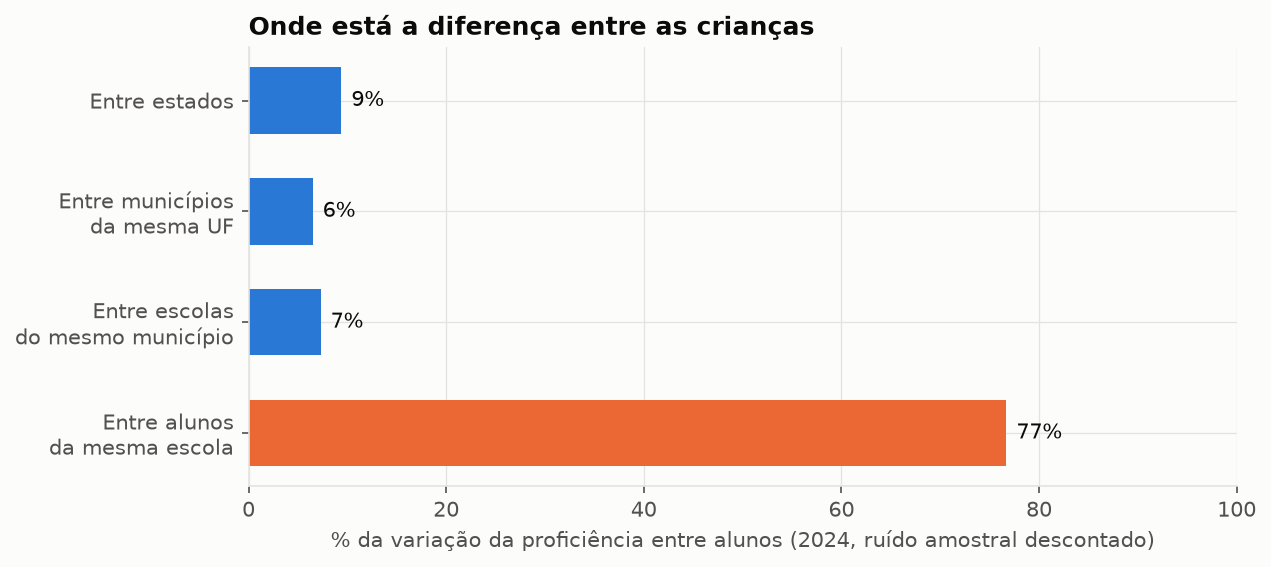

In [3]:
r = json.load(open('reports/escolas_resumo.json'))
display(pd.DataFrame({'proficiência': r['decomposicao_proficiencia']['pct_corrigido'], 'alfabetizado (0/1)': r['decomposicao_alfabetizado_0_1']['pct_corrigido']}))
display(Image('images/escolas_decomposicao.png'))

**77% da variação de proficiência está entre alunos da mesma escola.** Estado (9%), município (6%) e escola (7%) somam cerca de 23%. Qualquer modelo que só conheça o endereço da criança fica limitado a essa fatia.

## 3. Escolas do mesmo município

{'municipios_avaliados': 3258,
 'amplitude_mediana_pp': 27.7,
 'amplitude_mediana_so_acaso_pp': 15.9,
 'amplitude_real_estimada_pp': 22.7,
 'pct_com_amplitude_acima_de_30pp': 44.1}

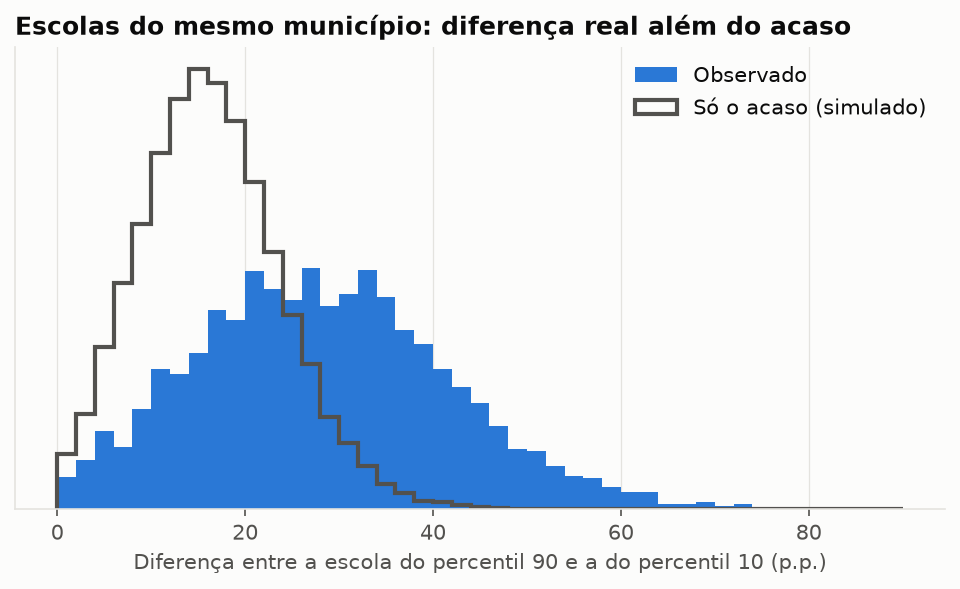

In [4]:
display(r['dispersao_municipio'])
display(Image('images/escolas_dispersao_municipio.png'))

A distância mediana entre a escola do percentil 90 e a do percentil 10 é de 28 p.p.; só o acaso de amostra produziria 16. A diferença real estimada é de **~23 p.p.**

In [5]:
r['escolas_criticas_escondidas']

{'municipios_que_bateram_a_meta': 2788,
 'escolas_criticas_nesses_municipios': 1530,
 'municipios_com_ao_menos_uma': 542,
 'pct_municipios_que_bateram_com_escola_critica': 19.4,
 'alunos_nessas_escolas': 68492,
 'esperadas_so_por_acaso': 756,
 'acima_do_acaso': 774}

Em municípios que **bateram a meta de 2024**, há 1.530 escolas municipais com menos de 40% de alfabetizados; o acaso explicaria cerca de 756. **Cerca de 770 escolas críticas reais ficam escondidas pela média do município.** Como não dá para separar uma a uma o real do acaso, a lista serve para verificação local, não para conclusão.

{'taxa_por_rede': {'Estadual': 61.7, 'Municipal': 58.8},
 'taxa_por_porte': {'até 10': 59.7,
  '11–25': 58.3,
  '26–50': 58.9,
  '51–100': 60.1,
  'mais de 100': 58.5},
 'alunos_por_porte': {'até 10': 8408,
  '11–25': 230173,
  '26–50': 462941,
  '51–100': 850925,
  'mais de 100': 562157}}

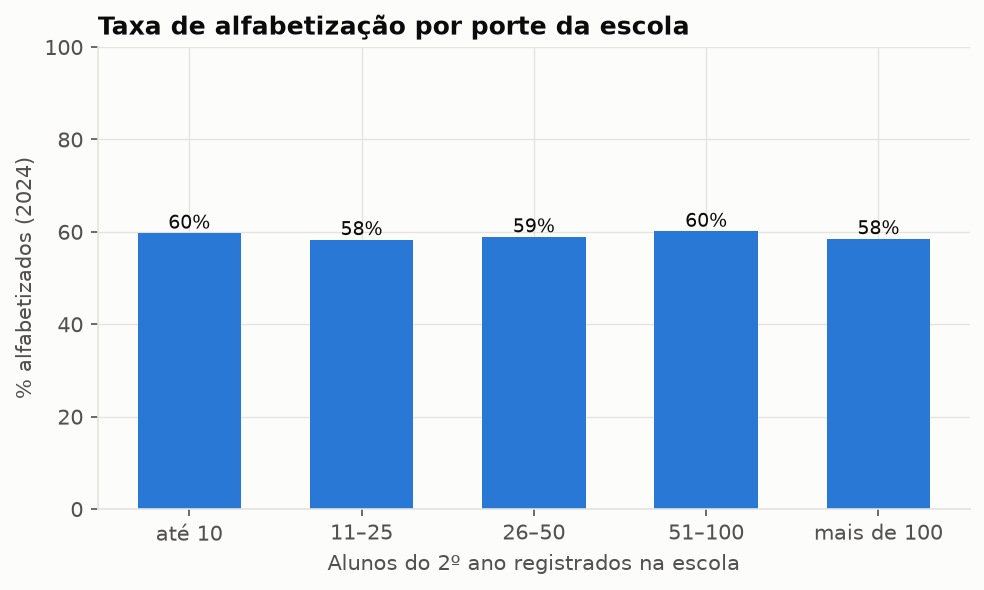

In [6]:
display(r['rede_e_porte'])
display(Image('images/escolas_porte.png'))

Rede estadual tem taxa um pouco maior (61,7% contra 58,8%). O porte da escola não muda a taxa.

## 4. Modelo por aluno

,modelo,params,auc_cv,desvio
0,logistica_so_municipio,{'C': 0.01},0.645,0.013
1,logistica_so_municipio,{'C': 0.1},0.645,0.013
2,logistica_so_municipio,{'C': 1},0.645,0.013
3,logistica_so_municipio,{'C': 10},0.645,0.013
4,logistica_municipio_e_escola,{'C': 0.01},0.652,0.011
5,logistica_municipio_e_escola,{'C': 0.1},0.652,0.011
6,logistica_municipio_e_escola,{'C': 1},0.652,0.011
7,logistica_municipio_e_escola,{'C': 10},0.652,0.011
8,boosting_municipio_e_escola,"{'learning_rate': 0.05, 'max_leaf_nodes': 15}",0.650,0.014
9,boosting_municipio_e_escola,"{'learning_rate': 0.05, 'max_leaf_nodes': 31}",0.652,0.014


,modelo,auc_cv,auc_teste,tipo,params
0,baseline (taxa nacional),0.500,0.500,piso,NaN
1,logistica_so_municipio,0.645,0.662,modelo,{'C': 0.01}
2,logistica_municipio_e_escola,0.652,0.663,modelo,{'C': 0.01}
3,boosting_municipio_e_escola,0.652,0.665,modelo,"{'learning_rate': 0.05, 'max_leaf_nodes': 31}"
4,teto: taxa real do municipio,NaN,0.685,teto,NaN
5,teto: taxa real da escola,NaN,0.741,teto,NaN


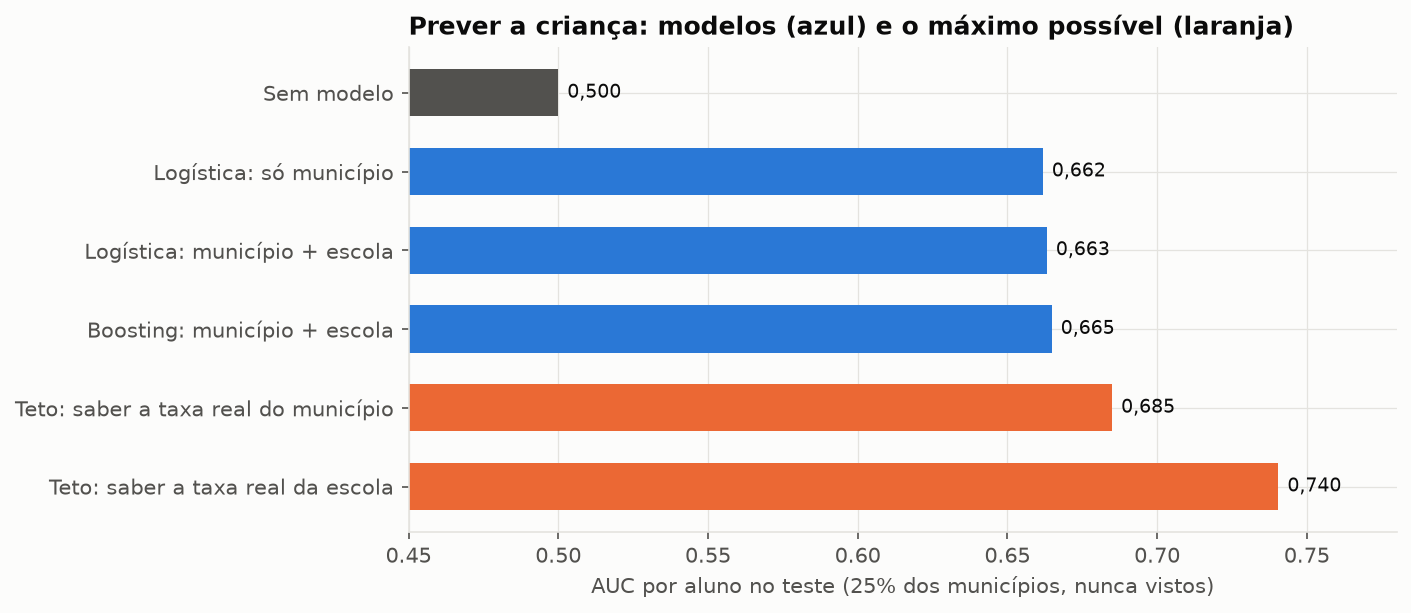

In [7]:
m = json.load(open('reports/resultado_modelo_aluno.json'))
display(pd.DataFrame(m['busca_em_grade']))
display(pd.DataFrame(m['comparacao_teste']))
display(Image('images/aluno_auc_comparacao.png'))

- **Protocolo:** 25% dos municípios guardados para teste; busca em grade (12 combinações) com `GroupKFold` por município no treino e AUC ponderada pelo peso dos alunos.
- AUC por aluno: **0,652** na validação e **0,663** no teste, em municípios nunca vistos. Sem sobreajuste.
- As variáveis de escola acrescentam pouco sobre o município.
- **Teto:** mesmo sabendo a taxa real da escola em 2024 (impossível na prática), a AUC no teste seria 0,741. O modelo percorre ~68% do caminho entre o acaso e esse teto.
- O que falta para prever a criança está dentro da sala de aula: frequência, avaliação diagnóstica, histórico do aluno. Nada disso está nos dados abertos.

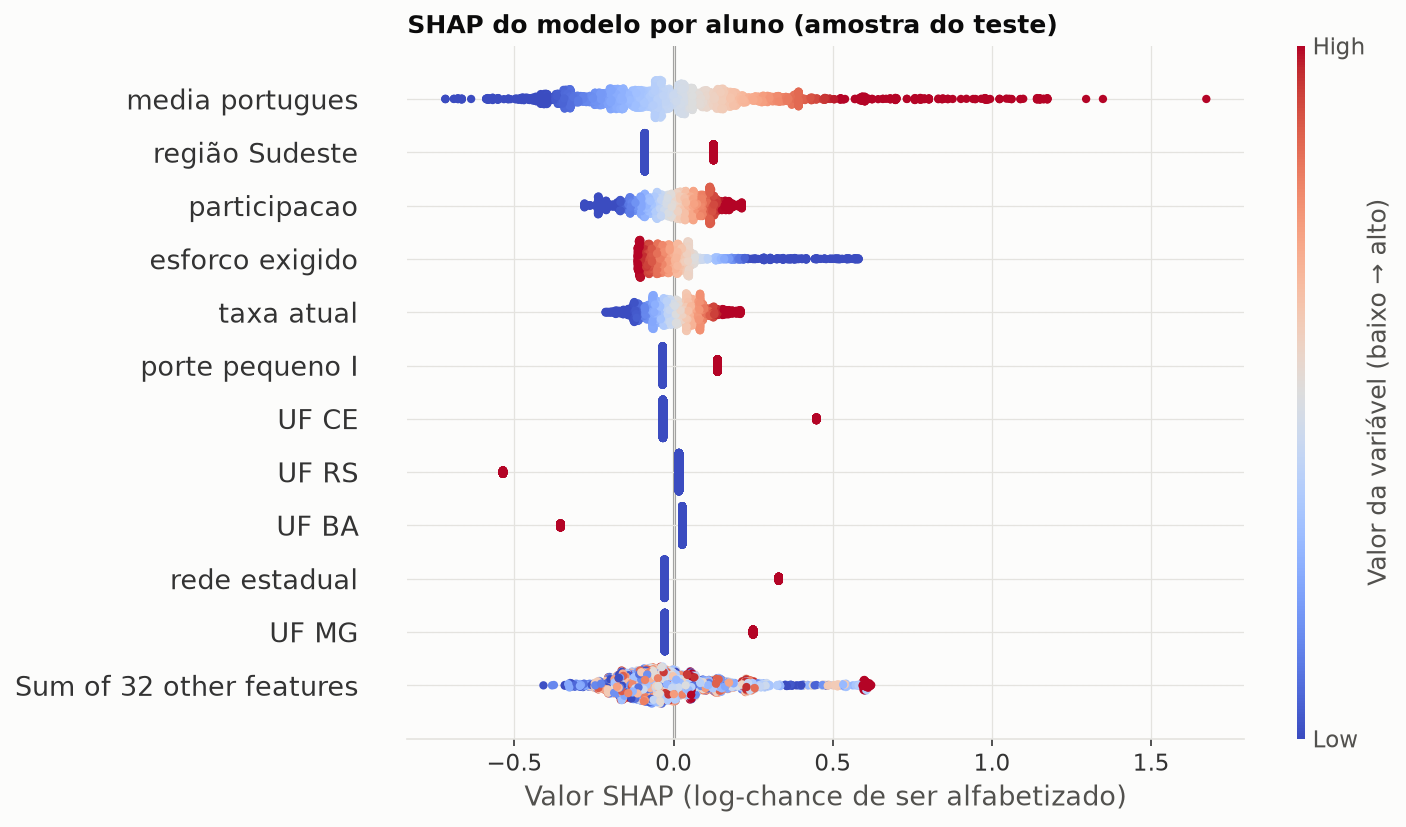

,SHAP médio,permutação (teste)
sigla_uf,0.406,3.130e-02
media_portugues,0.213,2.810e-02
regiao,0.149,5.400e-03
porte_municipio,0.118,2.500e-03
participacao,0.084,5.000e-03
esforco_exigido,0.072,3.400e-03
rede_escola,0.067,3.300e-03
taxa_atual,0.067,1.800e-03
log_populacao,0.042,-2.000e-04
log_pib_per_capita,0.041,1.000e-03


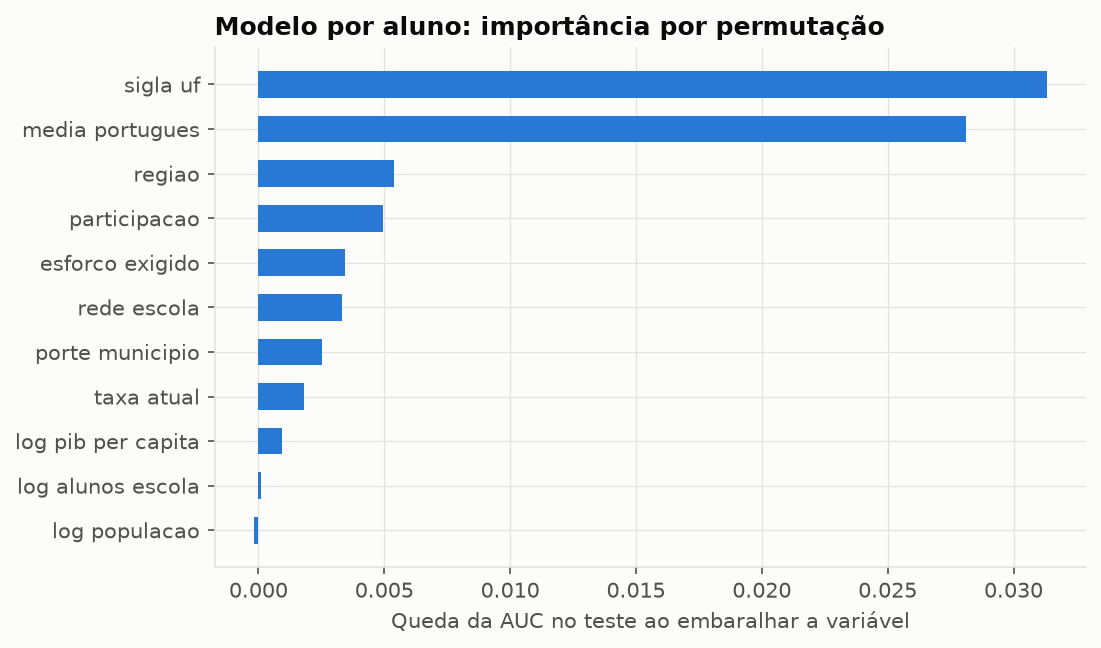

In [8]:
display(Image('images/aluno_shap_resumo.png'))
display(pd.DataFrame({'SHAP médio': m['shap_medio_por_variavel'], 'permutação (teste)': m['importancia_permutacao']}))
display(Image('images/aluno_importancia.png'))

UF e média de português do município dominam no SHAP e na permutação. A escola acrescenta pouco. É o mesmo padrão do modelo municipal: o contexto estadual pesa mais que qualquer característica local.